# ESP32 bird classifiers v4: crop-trained `isBird` + local species model

Trains two models for the Raspberry Pi hub from `D:\Datasets\ESP32Cam_confirmed`, then exports TFLite files and contracts.

1. **`isBird`**: a binary classifier for the crop the Pi actually scores: the motion blob, or the static-ROI fallback with 20% margin and a 160 px minimum. Its contract is a drop-in for `bird_inference.py` (`selected_crop_then_letterbox`, black letterbox, uint8 threshold).
2. **Species**: a classifier for a **bird crop**. It covers the species seen on camera plus regional feeder species from iNaturalist/CUB. The current server still feeds species the whole frame, so this model needs the small server change described in `DEPLOY.md` before you enable it.

Splits hold out **whole scenes** (camera + ROI placement), so the test metrics show how each model handles a camera angle it has never seen.

Run top to bottom. Set `QUICK_RUN = True` only to check the pipeline. A full run takes about 1–2 hours on the RTX 3060 laptop. Each finished model is written to disk before the next stage starts.


## 1. Configuration


In [1]:
# ---- Data -------------------------------------------------------------------
DATASET_ROOT = r"D:\Datasets\ESP32Cam_confirmed"
ANNOTATIONS_CSV = DATASET_ROOT + r"\bird_annotations.csv"
INVENTORY_CSV = DATASET_ROOT + r"\ESP32Cam_confirmed_manifest.csv"
# Outside data (species only). Missing roots are skipped; the species model then trains ESP32-only.
OUTSIDE_MANIFEST_DIRS = [DATASET_ROOT + r"\Manifests",
                         r"C:\Users\Joe\Desktop\ESP_Classifier\esp32_Classifier\Models\Manifests"]
INAT_IMAGE_ROOTS = [r"D:\Datasets\Animals", r"E:\Datasets\Animals", r"D:\Datasets\iNaturalist", r"E:\Datasets\iNaturalist"]
CUB_IMAGE_ROOTS = [r"D:\Datasets\CUB_200_2011\CUB_200_2011\images", r"E:\Datasets\CUB_200_2011\CUB_200_2011\images",
                   r"D:\Datasets\CUB_200\CUB_200_2011\images", r"E:\Datasets\CUB_200\CUB_200_2011\images"]
MODELS_DIR = r"C:\Users\Joe\Desktop\ESP_Classifier\esp32_Classifier\Models"
OUTPUT_ROOT = MODELS_DIR + r"\runs"

# Old models, scored on the same held-out crops for a before/after comparison (skipped if missing).
OLD_ISBIRD_DIR = MODELS_DIR + r"\runs\isbird_letterbox_224_20261010_173627"
OLD_SPECIES_DIR = MODELS_DIR + r"\runs\letterbox_224_20261009_131631"

SEED = 1234
QUICK_RUN = False

# ---- Scene split ---------------------------------------------------------------
# A scene is one camera at one ROI placement (legacy captures without camera metadata: one scene per day).
# Whole scenes are held out, separately per sensor, so the test measures unseen-angle performance.
VAL_SCENE_FRACTION = 0.15
TEST_SCENE_FRACTION = 0.15
MIN_HOLDOUT_SCENE_IMAGES = 60
MAX_HOLDOUT_SCENE_SHARE = 0.20          # never hold out a scene holding more than this share of a sensor's images
HOLDOUT_BIRD_RATE_RANGE = (0.15, 0.92)  # held-out scenes must contain both labels
SPECIES_TRAIN_RETENTION = 0.5           # do not hold out a scene that removes >50% of a species' ESP32 boxes
FORCE_VAL_SCENES = []                   # optional explicit scene ids; leave empty for the automatic rule
FORCE_TEST_SCENES = []

# ---- Pi crop contract (copied from server/motion_crop.py) -----------------------
PI_MARGIN_FRACTION = 0.20
PI_MIN_CROP = 160

# ---- isBird --------------------------------------------------------------------
WEIGHTS = "imagenet"
ISBIRD_IMG = 224
ISBIRD_ALPHA = 1.0
ISBIRD_POS_MIN_VISIBLE = 0.6      # a crop is "bird" if some box is >=60% inside it ...
ISBIRD_NEG_MAX_VISIBLE = 0.05     # ... and "not_bird" only if every box is <=5% inside; between = ambiguous, dropped
ISBIRD_MIN_BIRD_PX = 10           # birds smaller than this in the 224 input are ambiguous
ISBIRD_POS_MIX = {"static_roi": 0.55, "bird_blob": 0.45}
ISBIRD_NEG_MIX = {"static_roi_empty": 0.40, "random_blob_empty": 0.30, "same_scene_bird_free": 0.30}
ROI_SWAP_PROB = 0.35              # use another scene's ROI placement, so "feeder region" stops implying "bird"
ROI_JITTER_SHIFT = 0.12           # in ROI widths/heights
ROI_JITTER_LOG_SCALE = 0.25
MAX_FALSE_POSITIVE_RATE = 0.10    # threshold = best validation recall with at most this FPR (all crop types)

# ---- Species -------------------------------------------------------------------
SPECIES_IMG = 224
SPECIES_ALPHA = 1.0
# Regional feeder species that have not reached the camera yet; trained from iNaturalist/CUB only.
REGIONAL_EXTRA_SPECIES = [
    "American Goldfinch", "House Finch", "Dark-eyed Junco", "White-throated Sparrow", "Carolina Wren",
    "European Starling", "Common Grackle", "Red-winged Blackbird", "Hairy Woodpecker", "Red-breasted Nuthatch",
    "Brown-headed Cowbird", "American Robin", "Northern Mockingbird", "Chipping Sparrow", "Purple Finch",
    "American Tree Sparrow", "Northern Flicker", "Pine Siskin", "Rock Pigeon", "Gray Catbird",
]
SPECIES_BIRD_FRACTION = (0.28, 0.85)   # bird side / crop side: from static-ROI-loose to detector-box-tight
SPECIES_ASPECT_LOG = 0.4               # crop aspect jitter (static ROIs are portrait, motion crops square)
SPECIES_ESP32_SHARE = 0.65             # share of training draws from ESP32 crops when outside data exists
SPECIES_CLASS_BALANCE_POWER = 0.5      # per-class draw weight ~ count**power (0 = uniform, 1 = natural)
SPECIES_ARMS = ("esp32_plus_outside", "esp32_only")  # selected on validation macro recall
OUTSIDE_INAT_MIN_SCORE = 0.90

# ---- Shared training -------------------------------------------------------------
BATCH_SIZE = 32
EXAMPLES_PER_EPOCH = 9600
HEAD_EPOCHS = 3
FINE_TUNE_EPOCHS = 24
HEAD_LR = 1e-3
FINE_TUNE_PEAK_LR = 2e-4
WEIGHT_DECAY = 1e-4
FINE_TUNE_FROM_BLOCK = "block_6_expand"   # unfreeze from here up (old notebook: last 40 layers at 1e-5)
EARLY_STOP_PATIENCE = 6
LABEL_SMOOTHING = 0.05
REPRESENTATIVE_SAMPLES = 300
TFLITE_THREADS = 4

if QUICK_RUN:
    EXAMPLES_PER_EPOCH, HEAD_EPOCHS, FINE_TUNE_EPOCHS = 256, 1, 1
    EARLY_STOP_PATIENCE, REPRESENTATIVE_SAMPLES = 1, 16
    MIN_HOLDOUT_SCENE_IMAGES = 1


## 2. Environment and helpers


In [2]:
import hashlib, io, json, math, os, platform, random, re, time
from datetime import datetime, timezone
from pathlib import Path, PurePosixPath, PureWindowsPath

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
from PIL import Image, ImageOps

keras = tf.keras
for gpu in tf.config.list_physical_devices("GPU"):
    tf.config.experimental.set_memory_growth(gpu, True)
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)


def portable_path(raw):
    """Windows path <-> WSL /mnt/<drive> path, whichever this kernel needs."""
    raw = str(raw).strip()
    win = PureWindowsPath(raw)
    if win.drive:
        if os.name == "nt":
            return Path(raw)
        return Path("/mnt") / win.drive.rstrip(":").lower() / Path(*win.parts[1:])
    m = re.match(r"^/mnt/([A-Za-z])/(.*)$", raw.replace("\\", "/"))
    if m and os.name == "nt":
        return Path(f"{m.group(1).upper()}:/") / Path(*PurePosixPath(m.group(2)).parts)
    return Path(raw)


def sha256_file(path):
    h = hashlib.sha256()
    with Path(path).open("rb") as fh:
        for block in iter(lambda: fh.read(1 << 20), b""):
            h.update(block)
    return h.hexdigest()


def json_safe(v):
    if isinstance(v, dict):
        return {str(k): json_safe(x) for k, x in v.items()}
    if isinstance(v, (list, tuple)):
        return [json_safe(x) for x in v]
    if isinstance(v, Path):
        return str(v)
    if isinstance(v, np.ndarray):
        return json_safe(v.tolist())
    if isinstance(v, np.generic):
        v = v.item()
    if isinstance(v, float) and not math.isfinite(v):
        return None
    return v


def write_json(path, data):
    Path(path).write_text(json.dumps(json_safe(data), indent=2, allow_nan=False), encoding="utf-8")


def first_existing(paths, kind="dir"):
    for p in paths:
        q = portable_path(p)
        if (q.is_dir() if kind == "dir" else q.is_file()):
            return q
    return None


DATASET_ROOT_PATH = portable_path(DATASET_ROOT)
created_utc = datetime.now(timezone.utc)
RUN_NAME = f"esp32_classifiers_v4_{created_utc:%Y%m%dT%H%M%SZ}" + ("_quick" if QUICK_RUN else "")
RUN_DIR = portable_path(OUTPUT_ROOT) / RUN_NAME
(RUN_DIR / "isbird").mkdir(parents=True, exist_ok=False)
(RUN_DIR / "species").mkdir(parents=True, exist_ok=False)
print("Python", platform.python_version(), "| TensorFlow", tf.__version__)
print("GPUs:", tf.config.list_physical_devices("GPU"))
print("Run directory:", RUN_DIR)


I0000 00:00:1795070588.911560     614 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1795070589.442802     614 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1795070591.488975     614 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


Python 3.12.15 | TensorFlow 2.21.0
GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Run directory: /mnt/c/Users/Joe/Desktop/ESP_Classifier/esp32_Classifier/Models/runs/esp32_classifiers_v4_20261119T064312Z


## 3. Load annotations, inventory and capture sidecars

One record per image: boxes with species, plus camera ID, sensor, static ROI and deployment from the sidecar JSON. Images whose SHA-256 does not match the inventory are rejected.


In [3]:
ann = pd.read_csv(portable_path(ANNOTATIONS_CSV), encoding="utf-8-sig", low_memory=False)
inv = pd.read_csv(portable_path(INVENTORY_CSV), encoding="utf-8-sig", low_memory=False)
for col in ("xmin", "ymin", "xmax", "ymax", "width_px", "height_px"):
    ann[col] = pd.to_numeric(ann[col], errors="coerce")
assert inv["sample_id"].is_unique, "inventory sample_id values must be unique"
assert set(ann["sample_id"]) == set(inv["sample_id"]), "annotations and inventory list different images"


def parse_sidecar(path):
    d = json.loads(Path(path).read_text(encoding="utf-8"))
    cam = d.get("camera") or {}
    sensor = (cam.get("sensor") or {}).get("model") or d.get("camera_model") or "unknown"
    roi = ((cam.get("requested") or {}).get("motion") or {}).get("roi")
    ok_roi = (isinstance(roi, dict) and set(roi) >= {"x", "y", "width", "height"}
              and all(isinstance(roi[k], (int, float)) for k in ("x", "y", "width", "height"))
              and roi["width"] > 0 and roi["height"] > 0)
    camera_id = d.get("camera_id") or (d.get("device") or {}).get("camera_id")
    return {
        "camera_id": camera_id or "",
        "sensor": str(sensor),
        "roi": {k: float(roi[k]) for k in ("x", "y", "width", "height")} if ok_roi else None,
        "deployment_id": d.get("deployment_id") or "",
        "motion_selection_source": d.get("motion_selection_source") or "",
        "capture_source": d.get("source") or "",
    }


t0 = time.perf_counter()
records, rejected = [], []
boxed_rows = ann[ann["review_state"].eq("boxed") & ann["xmin"].notna()]
boxes_by_sample = {sid: g for sid, g in boxed_rows.groupby("sample_id")}
for row in inv.itertuples(index=False):
    image_path = DATASET_ROOT_PATH / row.image_filename
    sidecar_path = DATASET_ROOT_PATH / row.sidecar_filename
    if not image_path.is_file() or not sidecar_path.is_file():
        rejected.append((row.sample_id, "missing_file")); continue
    data = image_path.read_bytes()
    if hashlib.sha256(data).hexdigest() != row.image_sha256:
        rejected.append((row.sample_id, "image_sha256_mismatch")); continue
    meta = parse_sidecar(sidecar_path)
    g = boxes_by_sample.get(row.sample_id)
    W, H = int(row.width_px), int(row.height_px)
    if g is not None:
        b = g[["xmin", "ymin", "xmax", "ymax"]].to_numpy(np.float32)
        b[:, [0, 2]] = b[:, [0, 2]].clip(0, W); b[:, [1, 3]] = b[:, [1, 3]].clip(0, H)
        keep = (b[:, 2] - b[:, 0] >= 2) & (b[:, 3] - b[:, 1] >= 2)
        boxes, species = b[keep], g["species_name"].fillna("").astype(str).to_numpy()[keep]
    else:
        boxes, species = np.zeros((0, 4), np.float32), np.array([], dtype=object)
    stamp = re.match(r"capture_(\d{8}T\d{6})_(\d{6})Z", row.sample_id)
    when = pd.Timestamp(datetime.strptime("".join(stamp.groups()), "%Y%m%dT%H%M%S%f"), tz="UTC")
    records.append({
        "sample_id": row.sample_id, "jpeg": data, "width": W, "height": H,
        "boxes": boxes, "species": species, "has_bird": row.review_state == "boxed",
        "time": when, **meta,
    })
if rejected:
    print(f"rejected {len(rejected)} images:", pd.Series([r for _, r in rejected]).value_counts().to_dict())
assert records, "no usable images"

frames = pd.DataFrame([{k: v for k, v in r.items() if k not in ("jpeg", "boxes", "species")} for r in records])
frames["n_boxes"] = [len(r["boxes"]) for r in records]
frames["date"] = frames["time"].dt.strftime("%Y-%m-%d")
frames["local_hour"] = frames["time"].dt.tz_convert("America/New_York").dt.hour
print(f"loaded {len(records):,} images ({sum(len(r['jpeg']) for r in records) / 1e6:.0f} MB) in {time.perf_counter() - t0:.0f}s")
display(pd.crosstab([frames["sensor"], frames["camera_id"].replace("", "legacy (no id)")], frames["has_bird"], margins=True))
display(frames["motion_selection_source"].replace("", "(not recorded)").value_counts().to_frame("captures"))


loaded 6,184 images (284 MB) in 148s


has_bird                      False  True   All
sensor camera_id                               
OV2640 esp32cam-389e8af4e9d4    185   429   614
       legacy (no id)           410   596  1006
OV5640 esp32cam-b8aa6d0d5020   1578  2957  4535
       esp32cam-f4ae6d0d5020     20     9    29
All                            2193  3991  6184

,captures
motion_selection_source,
(not recorded),4515
static_roi_fallback,1639
dynamic_motion_blob,30


## 4. Scenes and the held-out-scene split

Each scene is one camera at one ROI placement, which so far also means one day. Validation and test take **whole scenes**, chosen separately for each sensor. A scene is skipped for holdout when it would take more than half of some species' camera boxes out of training. Burst frames, the angle and the day's lighting therefore never appear on both sides of the split.


In [4]:
def scene_id(row):
    if not row["camera_id"]:
        return f"legacy|{row['sensor']}|{row['date']}"
    roi = row["roi"]
    key = "full" if roi is None else ",".join(f"{roi[k]:.3f}" for k in ("x", "y", "width", "height"))
    return f"{row['camera_id']}|{key}"


frames["scene"] = frames.apply(scene_id, axis=1)
bad = frames["has_bird"] & frames["n_boxes"].eq(0)
if bad.any():
    print(f"dropping {int(bad.sum())} 'boxed' images that have no valid box")
keep_index = np.flatnonzero(~bad.to_numpy())
records = [records[i] for i in keep_index]
frames = frames.iloc[keep_index].reset_index(drop=True)

box_species = pd.DataFrame([(r["sample_id"], s) for r in records for s in r["species"] if s],
                           columns=["sample_id", "species"]).merge(frames[["sample_id", "scene"]], on="sample_id")
species_totals = box_species["species"].value_counts()

scenes = frames.groupby("scene").agg(images=("sample_id", "size"), bird_rate=("has_bird", "mean"),
                                     sensor=("sensor", "first"), days=("date", "nunique"),
                                     first=("time", "min")).sort_values("first")
rng_split = np.random.default_rng(SEED)
assignment = {s: "train" for s in scenes.index}
for s in FORCE_VAL_SCENES:
    assignment[s] = "validation"
for s in FORCE_TEST_SCENES:
    assignment[s] = "test"


def species_ok(candidate):
    """True if holding out `candidate` keeps >= SPECIES_TRAIN_RETENTION of every species' boxes in train."""
    held = {s for s, a in assignment.items() if a != "train"} | {candidate}
    held_counts = box_species[box_species["scene"].isin(held)]["species"].value_counts()
    for sp, total in species_totals.items():
        if total >= 10 and held_counts.get(sp, 0) > (1 - SPECIES_TRAIN_RETENTION) * total:
            return False
    return True


if not FORCE_VAL_SCENES and not FORCE_TEST_SCENES:
    for sensor, group in scenes.groupby("sensor"):
        total = group["images"].sum()
        lo, hi = HOLDOUT_BIRD_RATE_RANGE
        eligible = group[(group["images"] >= MIN_HOLDOUT_SCENE_IMAGES)
                         & (group["images"] <= MAX_HOLDOUT_SCENE_SHARE * total)
                         & group["bird_rate"].between(lo, hi)]
        order = list(eligible.index)
        rng_split.shuffle(order)
        targets = {"test": TEST_SCENE_FRACTION * total, "validation": VAL_SCENE_FRACTION * total}
        taken = {"test": 0, "validation": 0}
        for s in order:
            open_splits = [k for k in targets if taken[k] < targets[k]]
            if not open_splits:
                break
            if assignment[s] != "train" or not species_ok(s):
                continue
            # give the scene to whichever holdout split is furthest below its target
            split = min(open_splits, key=lambda k: taken[k] / targets[k])
            assignment[s] = split
            taken[split] += scenes.loc[s, "images"]

frames["split"] = frames["scene"].map(assignment)
scenes["split"] = scenes.index.map(assignment)
for split in ("validation", "test"):
    part = frames[frames["split"].eq(split)]
    if part.empty or part["has_bird"].nunique() < 2:
        raise RuntimeError(f"{split} split is empty or single-label; set FORCE_{split[:4].upper()}_SCENES by hand")
display(scenes)
display(pd.crosstab([frames["split"], frames["sensor"]], frames["has_bird"], margins=True))
display(pd.crosstab(box_species["species"], box_species["sample_id"].map(frames.set_index("sample_id")["split"])))
frames.drop(columns=["roi"]).to_csv(RUN_DIR / "frames_and_splits.csv", index=False)
scenes.to_csv(RUN_DIR / "scenes.csv")


,images,bird_rate,sensor,days,first,split
scene,,,,,,
legacy|OV2640|2026-10-05,1,0.000000,OV2640,1,2026-10-05 17:12:48.411763+00:00,train
legacy|OV2640|2026-10-06,11,0.545455,OV2640,1,2026-10-06 19:00:16.221717+00:00,train
legacy|OV2640|2026-10-07,241,0.887967,OV2640,1,2026-10-07 16:33:56.875663+00:00,train
legacy|OV2640|2026-10-12,20,0.400000,OV2640,1,2026-10-12 16:40:07.676866+00:00,train
legacy|OV2640|2026-10-14,709,0.507757,OV2640,1,2026-10-14 13:30:48.199324+00:00,train
legacy|OV2640|2026-10-20,24,0.333333,OV2640,1,2026-10-20 14:10:25.743948+00:00,train
"esp32cam-f4ae6d0d5020|0.000,0.000,1.000,1.000",3,0.000000,OV5640,1,2026-10-27 18:16:10.539727+00:00,train
"esp32cam-389e8af4e9d4|0.000,0.000,1.000,1.000",3,0.333333,OV2640,2,2026-10-27 18:21:20.917870+00:00,train
"esp32cam-389e8af4e9d4|0.143,0.271,0.293,0.462",195,0.687179,OV2640,1,2026-10-27 18:26:12.185379+00:00,train


has_bird           False  True   All
split      sensor                   
test       OV2640     37    59    96
           OV5640    244   459   703
train      OV2640    493   836  1329
           OV5640   1292  2293  3585
validation OV2640     65   130   195
           OV5640     62   214   276
All                 2193  3991  6184

sample_id,test,train,validation
species,,,
American Crow,0,230,0
Black-capped Chickadee,0,175,8
Blue Jay,2,306,5
Downy Woodpecker,4,12,1
House Sparrow,470,3318,741
Mourning Dove,314,670,0
Northern Cardinal,5,154,35
Red-bellied Woodpecker,0,5,0
Song Sparrow,0,67,0


## 5. Crop geometry shared with the Pi

`normalized_roi_bounds` and `final_crop_bounds` are copied from `server/motion_crop.py`, so a training "static ROI" crop is exactly what the Pi crops when motion localisation falls back. Labels come from the crop, not the frame: a crop is a bird only when a box is at least 60% inside it, and empty only when every box is at most 5% inside. Crops in between are dropped as ambiguous.


In [5]:
def normalized_roi_bounds(roi, width, height):
    x, y, w, h = (float(roi[k]) for k in ("x", "y", "width", "height"))
    return (max(0, int(math.floor(x * width))), max(0, int(math.floor(y * height))),
            min(width, int(math.ceil((x + w) * width))), min(height, int(math.ceil((y + h) * height))))


def final_crop_bounds(bounds, frame_w, frame_h, margin_fraction=PI_MARGIN_FRACTION, minimum_size=PI_MIN_CROP):
    """server/motion_crop.py: margin, minimum size, then shift inside the frame."""
    left, top, right, bottom = bounds
    left, top = max(0, min(int(left), frame_w - 1)), max(0, min(int(top), frame_h - 1))
    right, bottom = max(left + 1, min(int(math.ceil(right)), frame_w)), max(top + 1, min(int(math.ceil(bottom)), frame_h))
    width, height = right - left, bottom - top
    tw = min(frame_w, max(minimum_size, int(math.ceil(width * (1 + margin_fraction)))))
    th = min(frame_h, max(minimum_size, int(math.ceil(height * (1 + margin_fraction)))))
    cx, cy = (left + right) / 2, (top + bottom) / 2
    cl = min(max(0, int(math.floor(cx - tw / 2))), frame_w - tw)
    ct = min(max(0, int(math.floor(cy - th / 2))), frame_h - th)
    return cl, ct, cl + tw, ct + th


def clip_rect(l, t, r, b, W, H, min_size=8):
    """Float rectangle -> integer half-open rectangle inside the frame, shifted (not shrunk) when possible."""
    w, h = min(max(r - l, min_size), W), min(max(b - t, min_size), H)
    l = min(max(l, 0), W - w); t = min(max(t, 0), H - h)
    return int(math.floor(l)), int(math.floor(t)), int(math.floor(l)) + int(round(w)), int(math.floor(t)) + int(round(h))


def visible_fractions(boxes, crop):
    if not len(boxes):
        return np.zeros(0, np.float32)
    l, t, r, b = crop
    iw = np.clip(np.minimum(boxes[:, 2], r) - np.maximum(boxes[:, 0], l), 0, None)
    ih = np.clip(np.minimum(boxes[:, 3], b) - np.maximum(boxes[:, 1], t), 0, None)
    area = np.maximum((boxes[:, 2] - boxes[:, 0]) * (boxes[:, 3] - boxes[:, 1]), 1e-6)
    return (iw * ih / area).astype(np.float32)


def letterbox_scale(crop, size):
    return size / max(crop[2] - crop[0], crop[3] - crop[1])


def crop_label(record, crop, size=ISBIRD_IMG):
    """1 bird, 0 empty, -1 ambiguous (partial or too small to see after resizing)."""
    vis = visible_fractions(record["boxes"], crop)
    if not len(vis) or vis.max() <= ISBIRD_NEG_MAX_VISIBLE:
        return 0
    scale = letterbox_scale(crop, size)
    sides = np.minimum(record["boxes"][:, 2] - record["boxes"][:, 0], record["boxes"][:, 3] - record["boxes"][:, 1]) * scale
    if np.any((vis >= ISBIRD_POS_MIN_VISIBLE) & (sides >= ISBIRD_MIN_BIRD_PX)):
        return 1
    return -1


ALL_ROIS = [r["roi"] for r in records if r["roi"] is not None and r["roi"]["width"] < 0.95]


def jittered_roi(rng, roi):
    w, h = roi["width"], roi["height"]
    s = math.exp(rng.uniform(-ROI_JITTER_LOG_SCALE, ROI_JITTER_LOG_SCALE))
    a = math.exp(rng.uniform(-0.15, 0.15))
    nw, nh = min(0.98, w * s * a), min(0.98, h * s / a)
    cx = roi["x"] + w / 2 + rng.normal(0, ROI_JITTER_SHIFT) * w
    cy = roi["y"] + h / 2 + rng.normal(0, ROI_JITTER_SHIFT) * h
    x = min(max(cx - nw / 2, 0.0), 1.0 - nw); y = min(max(cy - nh / 2, 0.0), 1.0 - nh)
    return {"x": x, "y": y, "width": nw, "height": nh}


def static_roi_crop(record, roi=None):
    roi = roi or record["roi"]
    return final_crop_bounds(normalized_roi_bounds(roi, record["width"], record["height"]), record["width"], record["height"])


def bird_blob_crop(rng, record):
    boxes = record["boxes"]
    if len(boxes) > 1 and rng.random() < 0.25:
        x1, y1, x2, y2 = boxes[:, 0].min(), boxes[:, 1].min(), boxes[:, 2].max(), boxes[:, 3].max()
    else:
        x1, y1, x2, y2 = boxes[rng.integers(len(boxes))]
    bw, bh = x2 - x1, y2 - y1
    x1 -= rng.uniform(0, 0.5) * bw; x2 += rng.uniform(0, 0.5) * bw
    y1 -= rng.uniform(0, 0.5) * bh; y2 += rng.uniform(0, 0.5) * bh
    dx, dy = rng.normal(0, 0.15, 2) * max(bw, bh)
    rect = clip_rect(x1 + dx, y1 + dy, x2 + dx, y2 + dy, record["width"], record["height"], 4)
    return final_crop_bounds(rect, record["width"], record["height"])


def random_blob_crop(rng, record):
    W, H = record["width"], record["height"]
    w = math.exp(rng.uniform(math.log(20), math.log(260))); h = w * math.exp(rng.uniform(-0.5, 0.5))
    cx, cy = rng.uniform(0, W), rng.uniform(0, H)
    rect = clip_rect(cx - w / 2, cy - h / 2, cx + w / 2, cy + h / 2, W, H, 4)
    return final_crop_bounds(rect, W, H)


def training_roi(rng, record):
    if record["roi"] is None or record["roi"]["width"] >= 0.95 or rng.random() < ROI_SWAP_PROB:
        return jittered_roi(rng, ALL_ROIS[rng.integers(len(ALL_ROIS))])
    return jittered_roi(rng, record["roi"])


print(f"{len(ALL_ROIS):,} images carry a static ROI; legacy images borrow ROIs from other scenes")


5,153 images carry a static ROI; legacy images borrow ROIs from other scenes


## 6. `isBird` samples

Training draws are half birds, half empties. Every negative is something the Pi really scores: an empty feeder ROI, a false-motion blob in an empty frame, or a **bird-free crop from a frame that has a bird in it**. That last kind shares the camera, angle, feeder and lighting with the positives, which removes the feeder and the time of day as shortcuts. ROIs are jittered, and 35% are swapped for another scene's ROI.

Fixed evaluation crops (one per type, per image, with a fixed seed) score validation and test: `static_roi` is the deployed path, plus `bird_blob`, `random_blob_empty` and `same_scene_bird_free`.


In [6]:
split_of = dict(zip(frames["sample_id"], frames["split"]))
by_split = {s: [i for i, r in enumerate(records) if split_of[r["sample_id"]] == s] for s in ("train", "validation", "test")}
train_bird = [i for i in by_split["train"] if records[i]["has_bird"]]
train_empty = [i for i in by_split["train"] if not records[i]["has_bird"]]
print({k: len(v) for k, v in by_split.items()}, "| train bird frames", len(train_bird), "empty frames", len(train_empty))


def draw_isbird(rng, max_tries=12):
    """-> (record index, crop, label, crop type); the crop type is fixed first, then up to max_tries crops."""
    want = int(rng.random() < 0.5)
    mix = ISBIRD_POS_MIX if want else ISBIRD_NEG_MIX
    kinds, weights = list(mix), np.array(list(mix.values()), np.float64)
    kind = kinds[rng.choice(len(kinds), p=weights / weights.sum())]
    for _ in range(max_tries):
        if kind == "static_roi":
            i = train_bird[rng.integers(len(train_bird))]; crop = static_roi_crop(records[i], training_roi(rng, records[i]))
        elif kind == "bird_blob":
            i = train_bird[rng.integers(len(train_bird))]; crop = bird_blob_crop(rng, records[i])
        elif kind == "static_roi_empty":
            i = train_empty[rng.integers(len(train_empty))]; crop = static_roi_crop(records[i], training_roi(rng, records[i]))
        elif kind == "random_blob_empty":
            i = train_empty[rng.integers(len(train_empty))]; crop = random_blob_crop(rng, records[i])
        else:  # same_scene_bird_free
            i = train_bird[rng.integers(len(train_bird))]
            crop = random_blob_crop(rng, records[i]) if rng.random() < 0.6 else static_roi_crop(records[i], training_roi(rng, records[i]))
        if crop_label(records[i], crop) == want:
            return i, crop, want, kind
    return None


def fixed_isbird_eval(indices, seed):
    rng = np.random.default_rng(seed)
    rows = []
    for i in indices:
        r = records[i]
        candidates = []
        if r["roi"] is not None:
            candidates.append(("static_roi", static_roi_crop(r)))
        if r["has_bird"]:
            candidates.append(("bird_blob", bird_blob_crop(rng, r)))
            for _ in range(20):
                c = random_blob_crop(rng, r)
                if crop_label(r, c) == 0:
                    candidates.append(("same_scene_bird_free", c)); break
        else:
            candidates.append(("random_blob_empty", random_blob_crop(rng, r)))
        for kind, crop in candidates:
            label = crop_label(r, crop)
            if label >= 0:
                rows.append({"index": i, "sample_id": r["sample_id"], "kind": kind, "label": label,
                             "left": crop[0], "top": crop[1], "right": crop[2], "bottom": crop[3]})
    return pd.DataFrame(rows)


isbird_val = fixed_isbird_eval(by_split["validation"], SEED + 11)
isbird_test = fixed_isbird_eval(by_split["test"], SEED + 12)
for name, table in (("validation", isbird_val), ("test", isbird_test)):
    print(name); display(pd.crosstab(table["kind"], table["label"], margins=True))

check = [draw_isbird(np.random.default_rng(SEED + k)) for k in range(2000)]
check = pd.DataFrame([c for c in check if c is not None], columns=["index", "crop", "label", "kind"])
print("training draw mix (2,000 samples):"); display(check.groupby(["label", "kind"]).size().to_frame("draws"))


{'train': 4914, 'validation': 471, 'test': 799} | train bird frames 3129 empty frames 1785
validation


label,0,1,All
kind,,,
bird_blob,0,344,344
random_blob_empty,127,0,127
same_scene_bird_free,344,0,344
static_roi,128,342,470
All,599,686,1285


test


label,0,1,All
kind,,,
bird_blob,0,517,517
random_blob_empty,281,0,281
same_scene_bird_free,518,0,518
static_roi,283,516,799
All,1082,1033,2115


training draw mix (2,000 samples):


draws
label kind                       
0     random_blob_empty       311
      same_scene_bird_free    287
      static_roi_empty        397
1     bird_blob               454
      static_roi              551

## 7. Shared TensorFlow pipeline, model builder and training loop

Every image is cropped from its JPEG bytes held in memory, which avoids slow WSL reads of `/mnt/d`. It is then letterboxed on black with `tf.image.resize_with_pad(antialias=True)`, the same geometry `bird_inference.py` uses. Outside (iNat/CUB) crops are also degraded to look like ESP32 frames: downscaled, JPEG-compressed, noised and colour-shifted.


In [7]:
AUTOTUNE = tf.data.AUTOTUNE


def decode_crop_letterbox(jpeg, crop, size):
    """crop = [left, top, right, bottom] int32, half-open, inside the frame."""
    window = tf.stack([crop[1], crop[0], crop[3] - crop[1], crop[2] - crop[0]])
    image = tf.io.decode_and_crop_jpeg(jpeg, window, channels=3)
    image = tf.image.resize_with_pad(tf.cast(image, tf.float32), size, size, antialias=True)
    return tf.ensure_shape(image, (size, size, 3))


def camera_augment(image, strong_greyscale=0.05):
    image = tf.image.random_flip_left_right(image)
    image = tf.image.random_brightness(image, 18.0)
    image = tf.image.random_contrast(image, 0.85, 1.15)
    image = tf.image.random_saturation(image, 0.8, 1.2)
    image = image * tf.random.uniform([1, 1, 3], 0.92, 1.08)  # white-balance drift between cameras
    grey = tf.image.grayscale_to_rgb(tf.image.rgb_to_grayscale(image))
    image = tf.where(tf.random.uniform([]) < strong_greyscale, grey, image)
    return tf.clip_by_value(image, 0.0, 255.0)


def esp32_look(image, size):
    """Make a sharp iNat/CUB crop look like an ESP32 crop: low native resolution, JPEG, noise, colour cast."""
    native = tf.random.uniform([], 56, 170, dtype=tf.int32)
    image = tf.image.resize(tf.image.resize(image, [native, native], antialias=True), [size, size])
    quality = tf.random.uniform([], 15, 60, dtype=tf.int32)
    image = tf.cast(tf.image.adjust_jpeg_quality(tf.cast(tf.clip_by_value(image, 0, 255), tf.uint8), quality), tf.float32)
    image = image + tf.random.normal(tf.shape(image), 0.0, tf.random.uniform([], 1.0, 8.0))
    image = image * tf.random.uniform([1, 1, 3], 0.8, 1.2)
    return tf.clip_by_value(image, 0.0, 255.0)


def make_train_ds(generator, size, n_classes, onehot):
    signature = (tf.TensorSpec((), tf.string), tf.TensorSpec((4,), tf.int32),
                 tf.TensorSpec((), tf.int32), tf.TensorSpec((), tf.bool))

    def prepare(jpeg, crop, label, outside):
        image = decode_crop_letterbox(jpeg, crop, size)
        image = tf.cond(outside, lambda: esp32_look(image, size), lambda: image)
        image = camera_augment(image)
        target = tf.one_hot(label, n_classes) if onehot else tf.cast(tf.reshape(label, (1,)), tf.float32)
        return image, target

    return (tf.data.Dataset.from_generator(generator, output_signature=signature)
            .map(prepare, num_parallel_calls=AUTOTUNE)
            .batch(BATCH_SIZE, drop_remainder=True).prefetch(AUTOTUNE))


def make_eval_ds(jpegs, crops, size):
    ds = tf.data.Dataset.from_tensor_slices((list(jpegs), np.asarray(crops, np.int32)))
    return ds.map(lambda j, c: decode_crop_letterbox(j, c, size), num_parallel_calls=AUTOTUNE).batch(64).prefetch(AUTOTUNE)


def build_classifier(size, alpha, n_out, activation, name):
    backbone = keras.applications.MobileNetV2(input_shape=(size, size, 3), alpha=alpha, include_top=False, weights=WEIGHTS)
    backbone.trainable = False
    inputs = keras.Input((size, size, 3), name="image")
    x = keras.layers.Rescaling(1.0 / 127.5, offset=-1.0, name="scale_to_mobilenet")(inputs)
    x = backbone(x, training=False)  # BatchNorm stays in inference mode, even while fine-tuning
    x = keras.layers.GlobalAveragePooling2D(name="global_average_pool")(x)
    x = keras.layers.Dropout(0.3, name="dropout")(x)
    outputs = keras.layers.Dense(n_out, activation=activation, name="output")(x)
    return keras.Model(inputs, outputs, name=name), backbone


def unfreeze_from(backbone, layer_name):
    backbone.trainable = True
    names = [layer.name for layer in backbone.layers]
    start = names.index(layer_name)
    for k, layer in enumerate(backbone.layers):
        layer.trainable = k >= start and not isinstance(layer, keras.layers.BatchNormalization)
    return sum(1 for layer in backbone.layers if layer.trainable)


class SelectBest(keras.callbacks.Callback):
    """Score the validation crops each epoch with `score_fn`; keep the best weights; stop when stale."""

    def __init__(self, score_fn, path, patience, log):
        super().__init__()
        self.score_fn, self.path, self.patience, self.log = score_fn, str(path), patience, log
        self.best, self.wait = -np.inf, 0

    def on_epoch_end(self, epoch, logs=None):
        score = float(self.score_fn(self.model))
        self.log.append({"epoch": len(self.log) + 1, "loss": float((logs or {}).get("loss", np.nan)), "val_score": score})
        print(f"  validation score {score:.4f} (best {max(self.best, score):.4f})")
        if score > self.best:
            self.best, self.wait = score, 0
            self.model.save_weights(self.path)
        else:
            self.wait += 1
            if self.wait >= self.patience:
                self.model.stop_training = True


def train_two_stage(model, backbone, train_ds, loss, score_fn, out_dir):
    history = []
    steps = max(1, EXAMPLES_PER_EPOCH // BATCH_SIZE)
    best_path = Path(out_dir) / "best.weights.h5"
    model.compile(optimizer=keras.optimizers.Adam(HEAD_LR), loss=loss)
    print("stage 1: head only")
    selector = SelectBest(score_fn, best_path, EARLY_STOP_PATIENCE, history)
    model.fit(train_ds, epochs=HEAD_EPOCHS, steps_per_epoch=steps, callbacks=[selector], verbose=2)
    model.load_weights(best_path)
    trainable = unfreeze_from(backbone, FINE_TUNE_FROM_BLOCK)
    print(f"stage 2: fine-tune {trainable} backbone layers from {FINE_TUNE_FROM_BLOCK}")
    total = steps * FINE_TUNE_EPOCHS
    schedule = keras.optimizers.schedules.CosineDecay(
        FINE_TUNE_PEAK_LR * 0.05, decay_steps=max(1, total - steps), alpha=0.02,
        warmup_target=FINE_TUNE_PEAK_LR, warmup_steps=steps)
    model.compile(optimizer=keras.optimizers.AdamW(schedule, weight_decay=WEIGHT_DECAY), loss=loss)
    selector.wait = 0
    model.fit(train_ds, epochs=FINE_TUNE_EPOCHS, steps_per_epoch=steps, callbacks=[selector], verbose=2)
    model.load_weights(best_path)
    pd.DataFrame(history).to_csv(Path(out_dir) / "training_history.csv", index=False)
    return history


try:
    from ai_edge_litert.interpreter import Interpreter
except ImportError:
    Interpreter = tf.lite.Interpreter


def export_tflite(model, representative_images, out_dir, stem="model"):
    out_dir = Path(out_dir)
    float_path, uint8_path = out_dir / f"{stem}_float32.tflite", out_dir / f"{stem}_uint8.tflite"
    float_path.write_bytes(tf.lite.TFLiteConverter.from_keras_model(model).convert())
    converter = tf.lite.TFLiteConverter.from_keras_model(model)
    converter.optimizations = [tf.lite.Optimize.DEFAULT]
    converter.representative_dataset = lambda: ([img[None].astype(np.float32)] for img in representative_images)
    converter.target_spec.supported_ops = [tf.lite.OpsSet.TFLITE_BUILTINS_INT8]
    converter.inference_input_type = tf.uint8
    converter.inference_output_type = tf.uint8
    uint8_path.write_bytes(converter.convert())
    model.save(out_dir / f"{stem}.keras")
    return float_path, uint8_path


def tflite_run(path, images_ds):
    """-> raw outputs (N, K), dequantized outputs (N, K), tensor info."""
    interpreter = Interpreter(model_path=str(path), num_threads=TFLITE_THREADS)
    interpreter.allocate_tensors()
    inp, out = interpreter.get_input_details()[0], interpreter.get_output_details()[0]
    raw_rows = []
    for batch in images_ds:
        for image in batch.numpy():
            x = image[None].astype(np.float32)
            if np.issubdtype(inp["dtype"], np.integer):
                scale, zero = inp["quantization"]
                x = np.clip(np.rint(x / scale + zero), 0, 255).astype(inp["dtype"])
            interpreter.set_tensor(inp["index"], x)
            interpreter.invoke()
            raw_rows.append(interpreter.get_tensor(out["index"]).reshape(-1).copy())
    raw = np.stack(raw_rows)
    if np.issubdtype(out["dtype"], np.integer):
        scale, zero = out["quantization"]
        values = (raw.astype(np.float32) - zero) * scale
    else:
        values = raw.astype(np.float32)
    info = {"input_shape": [int(v) for v in inp["shape"]], "input_dtype": np.dtype(inp["dtype"]).name,
            "input_quantization": [float(inp["quantization"][0]), int(inp["quantization"][1])],
            "output_dtype": np.dtype(out["dtype"]).name,
            "output_quantization": [float(out["quantization"][0]), int(out["quantization"][1])]}
    return raw, values, info


## 8. Train, export and evaluate `isBird`

The checkpoint is chosen on validation PR-AUC. The threshold is chosen on **uint8 TFLite validation outputs** over all four crop types: the highest recall with at most `MAX_FALSE_POSITIVE_RATE` false positives. Test is scored once afterwards, overall and by crop type, sensor, scene and time of day. The old Oct 10 `isBird` is scored on the same test crops for comparison.


I0000 00:00:1795070747.787580     614 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 3582 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 3060 Laptop GPU, pci bus id: 0000:01:00.0, compute capability: 8.6
I0000 00:00:1795070748.236298     614 generator_dataset_op.cc:213] Memory patch applied: M_TRIM_THRESHOLD=128 kb was set.


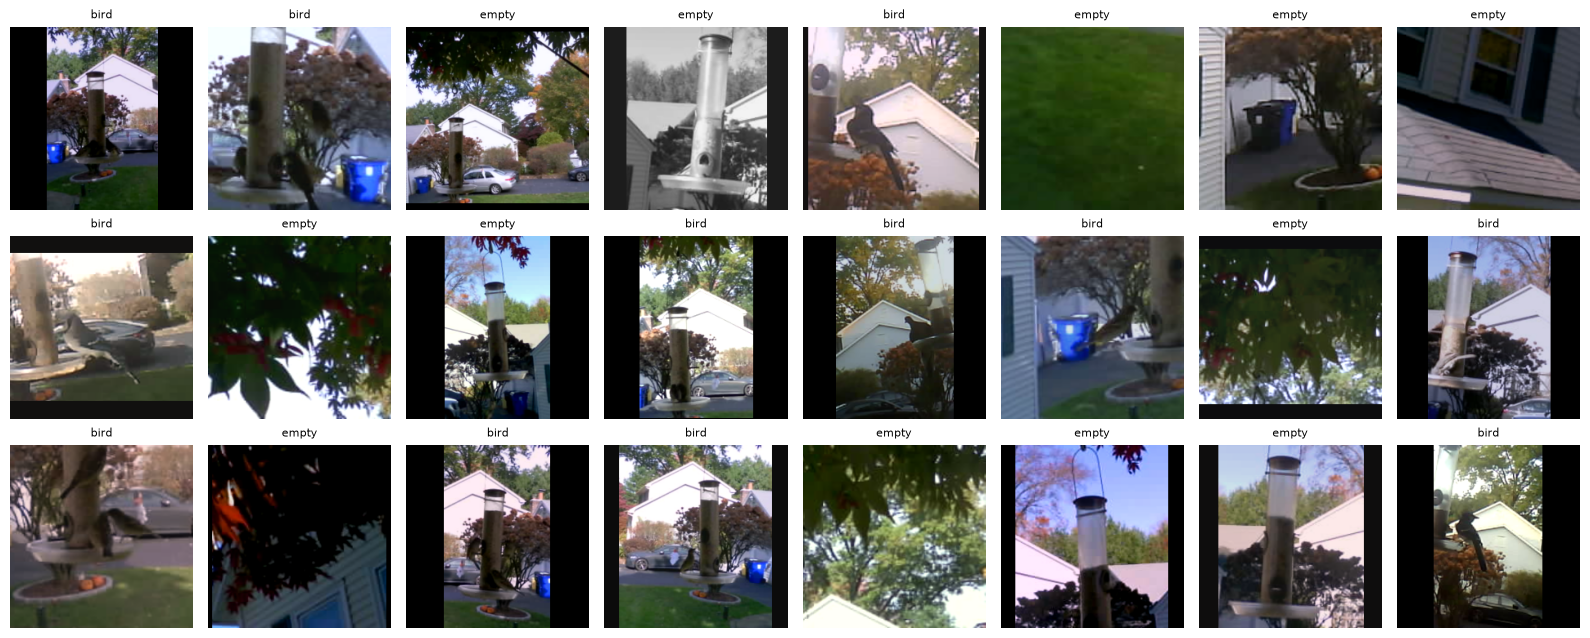

stage 1: head only
Epoch 1/3


/home/joe/venvs/ESPclassifier/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(
I0000 00:00:1795070754.679226     744 service.cc:153] XLA service 0x7f6cf8033600 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1795070754.679272     744 service.cc:161]   StreamExecutor [0]: NVIDIA GeForce RTX 3060 Laptop GPU, Compute Capability 8.6 (Driver: 13.4.0; Runtime: 12.9.0; Toolkit: 12.5.0; DNN: 9.27.0)
I0000 00:00:1795070754.803447     744 dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1795070755.456294     744 cuda_dnn.cc:461] Loaded cuDNN version 92700
I0000 00:00:1795070764.356960     744 device_compiler

  validation score 0.9278 (best 0.9278)
300/300 - 37s - 125ms/step - loss: 0.4656
Epoch 2/3
  validation score 0.9275 (best 0.9278)
300/300 - 10s - 35ms/step - loss: 0.3870
Epoch 3/3
  validation score 0.9322 (best 0.9322)
300/300 - 12s - 39ms/step - loss: 0.3745
stage 2: fine-tune 66 backbone layers from block_6_expand
Epoch 1/24
  validation score 0.9380 (best 0.9380)
300/300 - 37s - 122ms/step - loss: 0.3129
Epoch 2/24
  validation score 0.9423 (best 0.9423)
300/300 - 14s - 47ms/step - loss: 0.2415
Epoch 3/24
  validation score 0.7833 (best 0.9423)
300/300 - 14s - 45ms/step - loss: 0.2040
Epoch 4/24
  validation score 0.9212 (best 0.9423)
300/300 - 13s - 45ms/step - loss: 0.2019
Epoch 5/24
  validation score 0.9528 (best 0.9528)
300/300 - 14s - 47ms/step - loss: 0.1837
Epoch 6/24
  validation score 0.9508 (best 0.9528)
300/300 - 13s - 43ms/step - loss: 0.1764
Epoch 7/24
  validation score 0.9605 (best 0.9605)
300/300 - 14s - 48ms/step - loss: 0.1752
Epoch 8/24
  validation score 0.9

In [8]:
ISB_DIR = RUN_DIR / "isbird"


def isbird_generator():
    rng = np.random.default_rng(SEED + 1)
    while True:
        draw = draw_isbird(rng)
        if draw is None:
            continue
        i, crop, label, _ = draw
        yield records[i]["jpeg"], np.asarray(crop, np.int32), np.int32(label), False


def eval_inputs(table):
    return [records[i]["jpeg"] for i in table["index"]], table[["left", "top", "right", "bottom"]].to_numpy(np.int32)


val_jpegs, val_crops = eval_inputs(isbird_val)
isbird_val_ds = make_eval_ds(val_jpegs, val_crops, ISBIRD_IMG)
isbird_val_labels = isbird_val["label"].to_numpy()


def average_precision(labels, scores):
    order = np.argsort(-scores, kind="stable")
    labels = labels[order]
    tp = np.cumsum(labels); precision = tp / np.arange(1, len(labels) + 1)
    return float(np.sum(precision * labels) / max(1, labels.sum()))


def isbird_val_score(model):
    return average_precision(isbird_val_labels, model.predict(isbird_val_ds, verbose=0).reshape(-1))


isbird_train_ds = make_train_ds(isbird_generator, ISBIRD_IMG, 1, onehot=False)
preview_images, preview_labels = next(iter(isbird_train_ds))
fig, axes = plt.subplots(3, 8, figsize=(16, 6.5))
for ax, image, label in zip(axes.flat, preview_images.numpy(), preview_labels.numpy().reshape(-1)):
    ax.imshow(image.astype(np.uint8)); ax.set_title("bird" if label > 0.5 else "empty", fontsize=8); ax.axis("off")
plt.tight_layout(); plt.savefig(ISB_DIR / "training_preview.png", dpi=110); plt.show()

t0 = time.perf_counter()
isbird_model, isbird_backbone = build_classifier(ISBIRD_IMG, ISBIRD_ALPHA, 1, "sigmoid", "isbird_mobilenetv2")
isbird_history = train_two_stage(
    isbird_model, isbird_backbone, isbird_train_ds,
    keras.losses.BinaryCrossentropy(label_smoothing=LABEL_SMOOTHING), isbird_val_score, ISB_DIR)
isbird_minutes = (time.perf_counter() - t0) / 60
print(f"isBird trained in {isbird_minutes:.1f} min; best validation PR-AUC {max(h['val_score'] for h in isbird_history):.4f}")


In [9]:
rep_rng = np.random.default_rng(SEED + 5)
rep_images = []
while len(rep_images) < REPRESENTATIVE_SAMPLES:
    draw = draw_isbird(rep_rng)
    if draw is not None:
        i, crop, _, _ = draw
        rep_images.append(decode_crop_letterbox(records[i]["jpeg"], tf.constant(crop, tf.int32), ISBIRD_IMG).numpy())
ISB_FLOAT, ISB_UINT8 = export_tflite(isbird_model, rep_images, ISB_DIR)

val_raw, val_prob, isb_info = tflite_run(ISB_UINT8, isbird_val_ds)
val_raw, val_prob = val_raw.reshape(-1).astype(np.int64), val_prob.reshape(-1)
keras_val = isbird_model.predict(isbird_val_ds, verbose=0).reshape(-1)
print("uint8 vs Keras mean |delta|:", float(np.mean(np.abs(keras_val - val_prob))))


def binary_metrics(labels, decisions):
    labels, decisions = np.asarray(labels, bool), np.asarray(decisions, bool)
    tp = int(np.sum(decisions & labels)); fp = int(np.sum(decisions & ~labels))
    fn = int(np.sum(~decisions & labels)); tn = int(np.sum(~decisions & ~labels))
    ratio = lambda a, b: float(a / b) if b else float("nan")
    return {"n": len(labels), "birds": int(labels.sum()), "tp": tp, "fp": fp, "fn": fn, "tn": tn,
            "recall": ratio(tp, tp + fn), "false_positive_rate": ratio(fp, fp + tn),
            "precision": ratio(tp, tp + fp), "accuracy": ratio(tp + tn, len(labels))}


candidates = []
for t in np.unique(np.append(val_raw, 256)):
    m = binary_metrics(isbird_val_labels, val_raw >= t)
    candidates.append({"raw_threshold": int(t), **m})
candidates = pd.DataFrame(candidates)
candidates.to_csv(ISB_DIR / "validation_thresholds.csv", index=False)
eligible = candidates[candidates["false_positive_rate"] <= MAX_FALSE_POSITIVE_RATE]
chosen = eligible.sort_values(["recall", "raw_threshold"], ascending=[False, False]).iloc[0]
RAW_T = int(chosen["raw_threshold"])
out_scale, out_zero = isb_info["output_quantization"]
PROB_T = float((RAW_T - out_zero) * out_scale)
if chosen["recall"] < 0.5:
    print("WARNING: validation recall at the FPR budget is below 0.5; inspect validation_thresholds.csv before deploying")
print(f"threshold: uint8 output >= {RAW_T} (probability {PROB_T:.4f}); validation recall {chosen['recall']:.3f}, FPR {chosen['false_positive_rate']:.3f}")

test_jpegs, test_crops = eval_inputs(isbird_test)
isbird_test_ds = make_eval_ds(test_jpegs, test_crops, ISBIRD_IMG)
test_raw, test_prob, _ = tflite_run(ISB_UINT8, isbird_test_ds)
isbird_test = isbird_test.assign(raw=test_raw.reshape(-1), probability=test_prob.reshape(-1))
isbird_test["decision"] = isbird_test["raw"] >= RAW_T
isbird_val = isbird_val.assign(raw=val_raw, probability=val_prob, decision=val_raw >= RAW_T)
meta = frames.set_index("sample_id")


def hour_bucket(h):
    return "dawn 6-9" if h < 10 else "midday 10-14" if h < 15 else "dusk 15+"


for table in (isbird_val, isbird_test):
    table["sensor"] = table["sample_id"].map(meta["sensor"])
    table["scene"] = table["sample_id"].map(meta["scene"])
    table["time_of_day"] = table["sample_id"].map(meta["local_hour"]).map(hour_bucket)

rows = []
for split, table in (("validation", isbird_val), ("test", isbird_test)):
    rows.append({"split": split, "slice": "all", **binary_metrics(table["label"], table["decision"])})
    for column in ("kind", "sensor", "scene", "time_of_day"):
        for value, part in table.groupby(column):
            rows.append({"split": split, "slice": f"{column}={value}", **binary_metrics(part["label"], part["decision"])})
isbird_results = pd.DataFrame(rows)
isbird_results.to_csv(ISB_DIR / "results.csv", index=False)
isbird_test.drop(columns=["index"]).to_csv(ISB_DIR / "test_predictions.csv", index=False)
display(isbird_results[isbird_results["split"].eq("test")].round(3))


INFO:tensorflow:Assets written to: /tmp/tmpwcgypxre/assets


INFO:tensorflow:Assets written to: /tmp/tmpwcgypxre/assets


Saved artifact at '/tmp/tmpwcgypxre'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name='image')
Output Type:
  TensorSpec(shape=(None, 1), dtype=tf.float32, name=None)
Captures:
  140108142975248: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140108142976208: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140108142978512: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140108142977552: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140108142975632: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140108142978128: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140108142977744: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140108142979280: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140108142978896: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140108142978320: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140108142975056: Tens

W0000 00:00:1795071030.525524     614 tf_tfl_flatbuffer_helpers.cc:364] Ignored output_format.
W0000 00:00:1795071030.525572     614 tf_tfl_flatbuffer_helpers.cc:367] Ignored drop_control_dependency.
I0000 00:00:1795071030.526023     614 reader.cc:83] Reading SavedModel from: /tmp/tmpwcgypxre
I0000 00:00:1795071030.534935     614 reader.cc:52] Reading meta graph with tags { serve }
I0000 00:00:1795071030.534965     614 reader.cc:147] Reading SavedModel debug info (if present) from: /tmp/tmpwcgypxre
I0000 00:00:1795071030.624877     614 mlir_graph_optimization_pass.cc:437] MLIR V1 optimization pass is not enabled
I0000 00:00:1795071030.639716     614 loader.cc:236] Restoring SavedModel bundle.
I0000 00:00:1795071031.215427     614 loader.cc:220] Running initialization op on SavedModel bundle at path: /tmp/tmpwcgypxre
I0000 00:00:1795071031.334508     614 loader.cc:471] SavedModel load for tags { serve }; Status: success: OK. Took 808500 microseconds.


INFO:tensorflow:Assets written to: /tmp/tmpwjkmpjw6/assets


INFO:tensorflow:Assets written to: /tmp/tmpwjkmpjw6/assets


Saved artifact at '/tmp/tmpwjkmpjw6'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name='image')
Output Type:
  TensorSpec(shape=(None, 1), dtype=tf.float32, name=None)
Captures:
  140108142975248: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140108142976208: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140108142978512: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140108142977552: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140108142975632: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140108142978128: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140108142977744: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140108142979280: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140108142978896: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140108142978320: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140108142975056: Tens

/home/joe/venvs/ESPclassifier/lib/python3.12/site-packages/tensorflow/lite/python/convert.py:846: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn(
W0000 00:00:1795071039.254289     614 tf_tfl_flatbuffer_helpers.cc:364] Ignored output_format.
W0000 00:00:1795071039.254343     614 tf_tfl_flatbuffer_helpers.cc:367] Ignored drop_control_dependency.
I0000 00:00:1795071039.254497     614 reader.cc:83] Reading SavedModel from: /tmp/tmpwjkmpjw6
I0000 00:00:1795071039.264421     614 reader.cc:52] Reading meta graph with tags { serve }
I0000 00:00:1795071039.264453     614 reader.cc:147] Reading SavedModel debug info (if present) from: /tmp/tmpwjkmpjw6
I0000 00:00:1795071039.361029     614 loader.cc:236] Restoring SavedModel bundle.
I0000 00:00:1795071039.863071     614 loader.cc:220] Running initialization op on SavedModel bundle at path: /tmp/tmpwjkmpjw6
I0000 00:00:1795071039.978362     614 loader.cc:471] SavedModel load for ta

uint8 vs Keras mean |delta|: 0.013281634077429771
threshold: uint8 output >= 231 (probability 0.9023); validation recall 0.966, FPR 0.097


/home/joe/venvs/ESPclassifier/lib/python3.12/site-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)
Corrupt JPEG data: premature end of data segment


,split,slice,n,birds,tp,fp,fn,tn,recall,false_positive_rate,precision,accuracy
12,test,all,2115,1033,940,5,93,1077,0.910,0.005,0.995,0.954
13,test,kind=bird_blob,517,517,498,0,19,0,0.963,NaN,1.000,0.963
14,test,kind=random_blob_empty,281,0,0,0,0,281,NaN,0.000,NaN,1.000
15,test,kind=same_scene_bird_free,518,0,0,0,0,518,NaN,0.000,NaN,1.000
16,test,kind=static_roi,799,516,442,5,74,278,0.857,0.018,0.989,0.901
17,test,sensor=OV2640,251,118,102,4,16,129,0.864,0.030,0.962,0.920
18,test,sensor=OV5640,1864,915,838,1,77,948,0.916,0.001,0.999,0.958
19,test,"scene=esp32cam-389e8af4e9d4|0.328,0.276,0.287,...",251,118,102,4,16,129,0.864,0.030,0.962,0.920
20,test,"scene=esp32cam-b8aa6d0d5020|0.340,0.250,0.280,...",1864,915,838,1,77,948,0.916,0.001,0.999,0.958
21,test,time_of_day=dusk 15+,111,22,9,0,13,89,0.409,0.000,1.000,0.883


In [10]:
isbird_contract = {
    "model_file": ISB_UINT8.name,
    "task": "binary bird/not-bird classification of the Pi-selected crop",
    "labels": {"0": "not_bird", "1": "bird"},
    "positive_output": "bird_probability",
    "bird_probability_threshold": PROB_T,
    "uint8_output_threshold": RAW_T,
    "input_shape": isb_info["input_shape"],
    "input_dtype": isb_info["input_dtype"],
    "input_quantization": isb_info["input_quantization"],
    "output_dtype": isb_info["output_dtype"],
    "output_quantization": isb_info["output_quantization"],
    "color_order": "RGB",
    "jpeg_decode_channels": 3,
    "geometry": "selected_crop_then_letterbox",
    "geometry_location": "outside the model",
    "crop_source": "capture_motion_record.selection.final_bounds_px",
    "crop_coordinate_space": "original_decoded_frame_pixels",
    "crop_bounds_semantics": "half_open_left_top_right_bottom",
    "crop_is_final": True,
    "additional_runtime_margin": 0,
    "resize_method": "TensorFlow bilinear",
    "resize_antialias": True,
    "letterbox_padding_value": 0,
    "numeric_scaling": "[0,255] to [-1,1] inside the model",
    "trained_crop_types": list(ISBIRD_POS_MIX) + list(ISBIRD_NEG_MIX),
    "threshold_selection": f"max validation recall with FPR <= {MAX_FALSE_POSITIVE_RATE} over all validation crop types (uint8 TFLite)",
}
write_json(ISB_DIR / "inference_contract.json", isbird_contract)
write_json(ISB_DIR / "threshold.json", {"bird_probability_threshold": PROB_T, "uint8_output_threshold": RAW_T,
                                         "selected_on": "validation scenes, uint8 TFLite", "validation": chosen.to_dict()})
(ISB_DIR / "labels.txt").write_text("not_bird\nbird\n", encoding="utf-8")

# ---- Old isBird (Oct 10, whole-frame letterbox) on the same test crops and on whole frames ----
comparison = []
try:
    old_dir = portable_path(OLD_ISBIRD_DIR)
    old_model = next(p for p in (old_dir / "model_int8.tflite", old_dir / "model_float32.tflite") if p.is_file())
    old_t = json.loads((old_dir / "threshold.json").read_text())["bird_probability_threshold"]
    _, old_prob, _ = tflite_run(old_model, isbird_test_ds)
    old_dec = old_prob.reshape(-1) >= old_t
    comparison.append({"model": "old isBird (Oct 10)", "input": "same test crops", **binary_metrics(isbird_test["label"], old_dec)})
    for kind, part in isbird_test.assign(old=old_dec).groupby("kind"):
        comparison.append({"model": "old isBird (Oct 10)", "input": f"crops: {kind}", **binary_metrics(part["label"], part["old"])})
    test_frames = [i for i in by_split["test"]]
    whole = [(0, 0, records[i]["width"], records[i]["height"]) for i in test_frames]
    _, old_whole, _ = tflite_run(old_model, make_eval_ds([records[i]["jpeg"] for i in test_frames], whole, 224))
    comparison.append({"model": "old isBird (Oct 10)", "input": "whole test frames (its trained geometry)",
                       **binary_metrics([records[i]["has_bird"] for i in test_frames], old_whole.reshape(-1) >= old_t)})
except Exception as error:  # the comparison must never stop the run
    print("old isBird comparison skipped:", repr(error))
comparison.append({"model": "new isBird v4", "input": "same test crops", **binary_metrics(isbird_test["label"], isbird_test["decision"])})
for kind, part in isbird_test.groupby("kind"):
    comparison.append({"model": "new isBird v4", "input": f"crops: {kind}", **binary_metrics(part["label"], part["decision"])})
isbird_comparison = pd.DataFrame(comparison)
isbird_comparison.to_csv(ISB_DIR / "old_vs_new.csv", index=False)
display(isbird_comparison.round(3))
print("isBird artifacts written to", ISB_DIR)


/home/joe/venvs/ESPclassifier/lib/python3.12/site-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)
Corrupt JPEG data: premature end of data segment
Corrupt JPEG data: premature end of data segment


,model,input,n,birds,tp,fp,fn,tn,recall,false_positive_rate,precision,accuracy
0,old isBird (Oct 10),same test crops,2115,1033,689,447,344,635,0.667,0.413,0.607,0.626
1,old isBird (Oct 10),crops: bird_blob,517,517,287,0,230,0,0.555,NaN,1.000,0.555
2,old isBird (Oct 10),crops: random_blob_empty,281,0,0,81,0,200,NaN,0.288,0.000,0.712
3,old isBird (Oct 10),crops: same_scene_bird_free,518,0,0,140,0,378,NaN,0.270,0.000,0.730
4,old isBird (Oct 10),crops: static_roi,799,516,402,226,114,57,0.779,0.799,0.640,0.574
5,old isBird (Oct 10),whole test frames (its trained geometry),799,518,2,2,516,279,0.004,0.007,0.500,0.352
6,new isBird v4,same test crops,2115,1033,940,5,93,1077,0.910,0.005,0.995,0.954
7,new isBird v4,crops: bird_blob,517,517,498,0,19,0,0.963,NaN,1.000,0.963
8,new isBird v4,crops: random_blob_empty,281,0,0,0,0,281,NaN,0.000,NaN,1.000
9,new isBird v4,crops: same_scene_bird_free,518,0,0,0,0,518,NaN,0.000,NaN,1.000


isBird artifacts written to /mnt/c/Users/Joe/Desktop/ESP_Classifier/esp32_Classifier/Models/runs/esp32_classifiers_v4_20261119T064312Z/isbird


## 9. Species samples: one crop per bird box

Each labelled box becomes a crop whose size ranges from detector-tight (bird fills 85% of the crop) to static-ROI-loose (28%), with aspect jitter. A crop that would also take in more than half of a bird of a **different** species is redrawn. Evaluation uses three fixed crops per box: `tight` (box + 25%), `loose` (bird fills 35%) and `static_roi` (the Pi's actual crop, when the bird sits inside it and no other species does).


In [11]:
def norm_name(name):
    name = re.sub(r"[-_']", " ", str(name).lower())
    return re.sub(r"\s+", " ", name).strip()


CUB_ALIASES = {"cardinal": "northern cardinal", "mockingbird": "northern mockingbird",
               "tree sparrow": "american tree sparrow", "dark eyed junco": "dark eyed junco"}

esp32_boxes = []  # (record index, box index, species)
for i, r in enumerate(records):
    for k, sp in enumerate(r["species"]):
        if sp:
            esp32_boxes.append((i, k, sp))
esp32_boxes = pd.DataFrame(esp32_boxes, columns=["index", "box", "species"])
esp32_boxes["split"] = esp32_boxes["index"].map(lambda i: split_of[records[i]["sample_id"]])
display(pd.crosstab(esp32_boxes["species"], esp32_boxes["split"], margins=True))


def species_crop(rng, W, H, box, fraction=None, aspect_log=None, centre_jitter=0.8):
    x1, y1, x2, y2 = (float(v) for v in box)
    bw, bh = max(x2 - x1, 2.0), max(y2 - y1, 2.0)
    f = rng.uniform(*SPECIES_BIRD_FRACTION) if fraction is None else fraction
    a = math.exp(rng.uniform(-SPECIES_ASPECT_LOG, SPECIES_ASPECT_LOG) if aspect_log is None else aspect_log)
    side = max(bw, bh) / f
    cw, ch = max(side * math.sqrt(a), bw * 1.05), max(side / math.sqrt(a), bh * 1.05)
    cx = (x1 + x2) / 2 + rng.uniform(-1, 1) * (cw - bw) / 2 * centre_jitter
    cy = (y1 + y2) / 2 + rng.uniform(-1, 1) * (ch - bh) / 2 * centre_jitter
    return clip_rect(cx - cw / 2, cy - ch / 2, cx + cw / 2, cy + ch / 2, W, H, 16)


def intruder_free(record, k, crop):
    """No box of another species is more than half inside the crop."""
    vis = visible_fractions(record["boxes"], crop)
    other = record["species"] != record["species"][k]
    return not np.any(other & (vis > 0.5))


def esp32_species_crop(rng, i, k):
    r = records[i]
    for _ in range(6):
        crop = species_crop(rng, r["width"], r["height"], r["boxes"][k])
        if intruder_free(r, k, crop):
            return crop
    return species_crop(rng, r["width"], r["height"], r["boxes"][k], fraction=0.8, aspect_log=0.0, centre_jitter=0.0)


def fixed_species_eval(split):
    rng = np.random.default_rng(SEED + 21)
    rows = []
    for row in esp32_boxes[esp32_boxes["split"].eq(split)].itertuples(index=False):
        r = records[row.index]
        crops = {"tight": species_crop(rng, r["width"], r["height"], r["boxes"][row.box], 0.8, 0.0, 0.0),
                 "loose": species_crop(rng, r["width"], r["height"], r["boxes"][row.box], 0.35, 0.0, 0.3)}
        if r["roi"] is not None:
            c = static_roi_crop(r)
            if visible_fractions(r["boxes"][row.box:row.box + 1], c)[0] >= 0.9 and intruder_free(r, row.box, c):
                crops["static_roi"] = c
        for kind, crop in crops.items():
            if kind == "static_roi" or intruder_free(r, row.box, crop):
                rows.append({"index": row.index, "box": row.box, "sample_id": r["sample_id"], "species": row.species,
                             "kind": kind, "left": crop[0], "top": crop[1], "right": crop[2], "bottom": crop[3]})
    return pd.DataFrame(rows)


species_val_all = fixed_species_eval("validation")
species_test_all = fixed_species_eval("test")
display(pd.crosstab(species_test_all["species"], species_test_all["kind"]))


split,test,train,validation,All
species,,,,
American Crow,0,230,0,230
Black-capped Chickadee,0,175,8,183
Blue Jay,2,306,5,313
Downy Woodpecker,4,12,1,17
House Sparrow,470,3318,741,4529
Mourning Dove,314,670,0,984
Northern Cardinal,5,154,35,194
Red-bellied Woodpecker,0,5,0,5
Song Sparrow,0,67,0,67


kind,loose,static_roi,tight
species,,,
Blue Jay,2,2,2
Downy Woodpecker,4,4,4
House Sparrow,451,367,470
Mourning Dove,251,246,303
Northern Cardinal,4,4,5
White-breasted Nuthatch,4,4,5


## 10. Outside crops (iNaturalist + CUB), training only

Only species in the label set are loaded: the ones seen on camera plus `REGIONAL_EXTRA_SPECIES`. Images are EXIF-rotated only when that matches the manifest's recorded size, so the boxes stay aligned. If no image root is found, this section reports it and the species model trains on ESP32 crops only.


In [12]:
camera_species = sorted(esp32_boxes["species"].unique())
wanted = {norm_name(s): s for s in camera_species + REGIONAL_EXTRA_SPECIES}
outside = []  # dicts: jpeg, width, height, box, species, source
outside_report = {}


def load_outside_image(path, expected_w, expected_h, box):
    with Image.open(path) as im:
        raw_size = im.size
        rotated = ImageOps.exif_transpose(im)
        if (int(expected_w), int(expected_h)) == rotated.size:
            image = rotated.convert("RGB")
        elif (int(expected_w), int(expected_h)) == raw_size:
            image = im.convert("RGB")
        else:
            return None
    scale = min(1.0, 448 / max(image.size))
    if scale < 1.0:
        image = image.resize((max(1, round(image.width * scale)), max(1, round(image.height * scale))), Image.BILINEAR)
    buffer = io.BytesIO(); image.save(buffer, format="JPEG", quality=92)
    b = np.asarray(box, np.float32) * scale
    b[[0, 2]] = b[[0, 2]].clip(0, image.width); b[[1, 3]] = b[[1, 3]].clip(0, image.height)
    if b[2] - b[0] < 8 or b[3] - b[1] < 8:
        return None
    return buffer.getvalue(), image.width, image.height, b


manifest_dir = next((portable_path(d) for d in OUTSIDE_MANIFEST_DIRS
                     if (portable_path(d) / "bird_manifest.csv").is_file()), None)
inat_root = first_existing(INAT_IMAGE_ROOTS)
cub_root = first_existing(CUB_IMAGE_ROOTS)
print("manifests:", manifest_dir, "| iNat root:", inat_root, "| CUB root:", cub_root)
t0 = time.perf_counter()

if manifest_dir is not None:
    inat = pd.read_csv(manifest_dir / "bird_manifest.csv", encoding="utf-8-sig", low_memory=False,
                       usecols=["image_id", "relative_path", "absolute_path", "width", "height", "common_name"])
    inat["key"] = inat["common_name"].map(norm_name)
    inat = inat[inat["key"].isin(wanted)]
    boxes = pd.read_csv(manifest_dir / "inaturalist_bird_boxes.csv", encoding="utf-8-sig")
    boxes["image_id"] = boxes["source_id"].str.split(":").str[1].astype(int)
    boxes = boxes[boxes["score"] >= OUTSIDE_INAT_MIN_SCORE].sort_values("score", ascending=False).drop_duplicates("image_id")
    inat = inat.merge(boxes[["image_id", "x", "y", "w", "h"]], on="image_id")
    if QUICK_RUN:
        inat = inat.groupby("key").head(3)
    loaded = 0
    for row in inat.itertuples(index=False):
        rel = PurePosixPath(str(row.relative_path).replace("\\", "/"))
        candidates = [portable_path(row.absolute_path), inat_root.joinpath(*rel.parts) if inat_root else None,
                      inat_root.joinpath(*rel.parts[1:]) if inat_root and len(rel.parts) > 1 else None]
        path = next((p for p in candidates if p is not None and p.is_file()), None)
        if path is None:
            continue
        result = load_outside_image(path, row.width, row.height, (row.x, row.y, row.x + row.w, row.y + row.h))
        if result:
            jpeg, w, h, b = result
            outside.append({"jpeg": jpeg, "width": w, "height": h, "box": b, "species": wanted[row.key], "source": "inaturalist"})
            loaded += 1
    outside_report["inaturalist"] = {"candidates": len(inat), "loaded": loaded}

if manifest_dir is not None and (manifest_dir / "cub_200_2011_image_manifest.csv").is_file():
    cub = pd.read_csv(manifest_dir / "cub_200_2011_image_manifest.csv", low_memory=False,
                      usecols=["relative_path", "image_path", "class_name_friendly", "bbox_x", "bbox_y", "bbox_width", "bbox_height",
                               "width_px", "height_px"])
    cub["key"] = cub["class_name_friendly"].map(norm_name).map(lambda k: CUB_ALIASES.get(k, k))
    cub = cub[cub["key"].isin(wanted)]
    if QUICK_RUN:
        cub = cub.groupby("key").head(3)
    loaded = 0
    for row in cub.itertuples(index=False):
        options = [portable_path(row.image_path), cub_root.joinpath(*PurePosixPath(str(row.relative_path).replace("\\", "/")).parts) if cub_root else None]
        path = next((p for p in options if p is not None and p.is_file()), None)
        if path is None:
            continue
        result = load_outside_image(path, row.width_px, row.height_px,
                                    (row.bbox_x, row.bbox_y, row.bbox_x + row.bbox_width, row.bbox_y + row.bbox_height))
        if result:
            jpeg, w, h, b = result
            outside.append({"jpeg": jpeg, "width": w, "height": h, "box": b, "species": wanted[row.key], "source": "cub"})
            loaded += 1
    outside_report["cub"] = {"candidates": len(cub), "loaded": loaded}

print(f"outside crops loaded in {time.perf_counter() - t0:.0f}s:", outside_report)
outside_counts = pd.Series([o["species"] for o in outside], dtype=object).value_counts()
display(outside_counts.to_frame("outside images"))


manifests: /mnt/d/Datasets/ESP32Cam_confirmed/Manifests | iNat root: /mnt/d/Datasets/iNaturalist | CUB root: /mnt/d/Datasets/CUB_200/CUB_200_2011/images
outside crops loaded in 126s: {'inaturalist': {'candidates': 1256, 'loaded': 1256}, 'cub': {'candidates': 1136, 'loaded': 1136}}


,outside images
American Tree Sparrow,107
White-throated Sparrow,107
Purple Finch,106
Chipping Sparrow,105
Northern Mockingbird,105
Carolina Wren,102
Gray Catbird,100
American Goldfinch,100
American Crow,99
Song Sparrow,98


## 11. Train the species arms

`esp32_plus_outside` covers every camera species plus the regional extras, with a fixed share of outside draws. `esp32_only` covers only species that have camera training boxes. Draws are class-balanced with `count ** SPECIES_CLASS_BALANCE_POWER`, so House Sparrow (two-thirds of the boxes) cannot dominate. The arm with the better **validation macro recall over camera species** (tight + loose crops) is kept. Each arm's files are saved as soon as it finishes.


In [13]:
SP_DIR = RUN_DIR / "species"
train_boxes = esp32_boxes[esp32_boxes["split"].eq("train")]


def arm_classes(arm):
    camera_train = sorted(train_boxes["species"].unique())
    if arm == "esp32_only" or not outside:
        return camera_train
    return sorted(set(camera_train) | set(outside_counts.index))


def species_val_score_factory(classes, table):
    scored = set(classes) & set(train_boxes["species"])  # same species set for every arm
    table = table[table["kind"].isin(["tight", "loose"]) & table["species"].isin(scored)].reset_index(drop=True)
    ds = make_eval_ds([records[i]["jpeg"] for i in table["index"]],
                      table[["left", "top", "right", "bottom"]].to_numpy(np.int32), SPECIES_IMG)
    truth = table["species"].map({c: k for k, c in enumerate(classes)}).to_numpy()

    def score(model):
        pred = model.predict(ds, verbose=0).argmax(axis=1)
        recalls = [np.mean(pred[truth == c] == c) for c in np.unique(truth)]
        return float(np.mean(recalls)) if recalls else 0.0
    return score


def species_generator_factory(classes, use_outside):
    index_of = {c: k for k, c in enumerate(classes)}
    esp_by_class = {c: g[["index", "box"]].to_numpy() for c, g in train_boxes.groupby("species") if c in index_of}
    out_by_class = {}
    if use_outside:
        for k, o in enumerate(outside):
            if o["species"] in index_of:
                out_by_class.setdefault(o["species"], []).append(k)
    esp_classes = sorted(esp_by_class)
    esp_w = np.array([len(esp_by_class[c]) ** SPECIES_CLASS_BALANCE_POWER for c in esp_classes]); esp_w /= esp_w.sum()
    out_classes = sorted(out_by_class)
    out_w = np.array([len(out_by_class[c]) ** SPECIES_CLASS_BALANCE_POWER for c in out_classes]) if out_classes else None
    if out_w is not None:
        out_w = out_w / out_w.sum()
    esp_share = SPECIES_ESP32_SHARE if out_classes else 1.0

    def generator():
        rng = np.random.default_rng(SEED + 31)
        while True:
            if rng.random() < esp_share:
                c = esp_classes[rng.choice(len(esp_classes), p=esp_w)]
                i, k = esp_by_class[c][rng.integers(len(esp_by_class[c]))]
                yield records[i]["jpeg"], np.asarray(esp32_species_crop(rng, i, k), np.int32), np.int32(index_of[c]), False
            else:
                c = out_classes[rng.choice(len(out_classes), p=out_w)]
                o = outside[out_by_class[c][rng.integers(len(out_by_class[c]))]]
                crop = species_crop(rng, o["width"], o["height"], o["box"])
                yield o["jpeg"], np.asarray(crop, np.int32), np.int32(index_of[c]), True
    return generator


arm_results = {}
arms = [a for a in SPECIES_ARMS if not (a == "esp32_plus_outside" and not outside)]
for arm in arms:
    arm_dir = SP_DIR / arm
    arm_dir.mkdir(exist_ok=True)
    classes = arm_classes(arm)
    print(f"\n=== species arm {arm}: {len(classes)} classes ===")
    gen = species_generator_factory(classes, use_outside=(arm != "esp32_only"))
    ds = make_train_ds(gen, SPECIES_IMG, len(classes), onehot=True)
    model, backbone = build_classifier(SPECIES_IMG, SPECIES_ALPHA, len(classes), "softmax", "species_mobilenetv2")
    t0 = time.perf_counter()
    history = train_two_stage(model, backbone, ds,
                              keras.losses.CategoricalCrossentropy(label_smoothing=2 * LABEL_SMOOTHING),
                              species_val_score_factory(classes, species_val_all), arm_dir)
    (arm_dir / "labels.txt").write_text("\n".join(classes) + "\n", encoding="utf-8")
    rep = []
    for jpeg, crop, _, is_out in gen():
        image = decode_crop_letterbox(jpeg, tf.constant(crop), SPECIES_IMG)
        rep.append((esp32_look(image, SPECIES_IMG) if is_out else image).numpy())
        if len(rep) >= REPRESENTATIVE_SAMPLES:
            break
    float_path, uint8_path = export_tflite(model, rep, arm_dir)
    arm_results[arm] = {"classes": classes, "dir": arm_dir, "float": float_path, "uint8": uint8_path,
                        "best_val_macro_recall": max(h["val_score"] for h in history),
                        "minutes": (time.perf_counter() - t0) / 60}
    print(f"{arm}: best validation macro recall {arm_results[arm]['best_val_macro_recall']:.4f} "
          f"in {arm_results[arm]['minutes']:.1f} min")
    del model, backbone, ds
    keras.backend.clear_session()

best_arm = max(arm_results, key=lambda a: arm_results[a]["best_val_macro_recall"])
print("selected species arm:", best_arm)



=== species arm esp32_plus_outside: 31 classes ===
stage 1: head only
Epoch 1/3


/home/joe/venvs/ESPclassifier/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(
I0000 00:00:1795071219.387884     744 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_138866__.117


  validation score 0.2671 (best 0.2671)
300/300 - 25s - 84ms/step - loss: 2.3849
Epoch 2/3
  validation score 0.1994 (best 0.2671)
300/300 - 11s - 37ms/step - loss: 1.9744
Epoch 3/3
  validation score 0.2363 (best 0.2671)
300/300 - 11s - 38ms/step - loss: 1.8624
stage 2: fine-tune 66 backbone layers from block_6_expand
Epoch 1/24


I0000 00:00:1795071273.431819     744 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_160268__.191


  validation score 0.2191 (best 0.2671)
300/300 - 28s - 93ms/step - loss: 1.8128
Epoch 2/24
  validation score 0.4824 (best 0.4824)
300/300 - 14s - 48ms/step - loss: 1.6151
Epoch 3/24
  validation score 0.3113 (best 0.4824)
300/300 - 12s - 41ms/step - loss: 1.4281
Epoch 4/24
  validation score 0.3241 (best 0.4824)
300/300 - 12s - 41ms/step - loss: 1.2966
Epoch 5/24
  validation score 0.3245 (best 0.4824)
300/300 - 12s - 41ms/step - loss: 1.2287
Epoch 6/24
  validation score 0.4473 (best 0.4824)
300/300 - 12s - 41ms/step - loss: 1.1871
Epoch 7/24
  validation score 0.3111 (best 0.4824)
300/300 - 12s - 41ms/step - loss: 1.1234
Epoch 8/24
  validation score 0.3341 (best 0.4824)
300/300 - 13s - 42ms/step - loss: 1.0847
INFO:tensorflow:Assets written to: /tmp/tmph9_l2cl3/assets


INFO:tensorflow:Assets written to: /tmp/tmph9_l2cl3/assets


... (15 outputs left out)

INFO:tensorflow:Assets written to: /tmp/tmpundcqetw/assets


Saved artifact at '/tmp/tmpundcqetw'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name='image')
Output Type:
  TensorSpec(shape=(None, 11), dtype=tf.float32, name=None)
Captures:
  140100695919312: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140100695920080: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140100695920272: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140100695919504: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140100695919888: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140100695919120: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140100695920656: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140100695920464: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140100695917968: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140100695920848: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140100695921040: Ten

/home/joe/venvs/ESPclassifier/lib/python3.12/site-packages/tensorflow/lite/python/convert.py:846: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn(
W0000 00:00:1795071597.115314     614 tf_tfl_flatbuffer_helpers.cc:364] Ignored output_format.
W0000 00:00:1795071597.115374     614 tf_tfl_flatbuffer_helpers.cc:367] Ignored drop_control_dependency.
I0000 00:00:1795071597.115531     614 reader.cc:83] Reading SavedModel from: /tmp/tmpundcqetw
I0000 00:00:1795071597.123072     614 reader.cc:52] Reading meta graph with tags { serve }
I0000 00:00:1795071597.123111     614 reader.cc:147] Reading SavedModel debug info (if present) from: /tmp/tmpundcqetw
I0000 00:00:1795071597.202213     614 loader.cc:236] Restoring SavedModel bundle.
I0000 00:00:1795071597.698229     614 loader.cc:220] Running initialization op on SavedModel bundle at path: /tmp/tmpundcqetw
I0000 00:00:1795071597.814065     614 loader.cc:471] SavedModel load for ta

esp32_only: best validation macro recall 0.4317 in 3.2 min
selected species arm: esp32_plus_outside


## 12. Species evaluation, confidence threshold, contract and old-vs-new

Test crops are scored once with each arm's uint8 model. `suggested_min_confidence` is the lowest top-1 probability at which validation predictions are at least 90% correct. Below it, the hub should log "unidentified bird" and leave the species name off. The old species model (179 CUB/iNat classes, whole frame) is scored on whole single-species test frames, which is how the server runs it today, and on tight crops.


/home/joe/venvs/ESPclassifier/lib/python3.12/site-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)
/home/joe/venvs/ESPclassifier/lib/python3.12/site-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)
Corrupt JPEG data: premature end of data segment
Corrupt JPEG data: premature end of data segment
/home/joe/venvs/ESPclassifier/lib/python3.12/site-packages/tenso

,arm,split,crops,n,top1,top3,macro_recall,not_in_label_set
0,esp32_plus_outside,validation,all,2186,0.393,0.879,0.382,0
1,esp32_plus_outside,validation,tight,790,0.392,0.780,0.388,0
2,esp32_plus_outside,validation,loose,726,0.598,0.948,0.413,0
3,esp32_plus_outside,validation,static_roi,670,0.172,0.921,0.335,0
4,esp32_plus_outside,test,all,2132,0.493,0.879,0.451,0
5,esp32_plus_outside,test,tight,789,0.504,0.835,0.414,0
6,esp32_plus_outside,test,loose,716,0.672,0.941,0.601,0
7,esp32_plus_outside,test,static_roi,627,0.276,0.863,0.319,0
8,esp32_only,validation,all,2186,0.503,0.861,0.336,0
9,esp32_only,validation,tight,790,0.824,0.957,0.389,0


,arm,species,test_recall,test_crops,camera_train_boxes
0,esp32_plus_outside,Blue Jay,0.833,6,306
1,esp32_plus_outside,Downy Woodpecker,0.083,12,12
2,esp32_plus_outside,House Sparrow,0.452,1288,3318
3,esp32_plus_outside,Mourning Dove,0.568,800,670
4,esp32_plus_outside,Northern Cardinal,0.462,13,154
5,esp32_plus_outside,White-breasted Nuthatch,0.308,13,178
6,esp32_only,Blue Jay,0.833,6,306
7,esp32_only,Downy Woodpecker,0.000,12,12
8,esp32_only,House Sparrow,0.709,1288,3318
9,esp32_only,Mourning Dove,0.104,800,670


suggested_min_confidence 1.000: names 0.0% of test crops


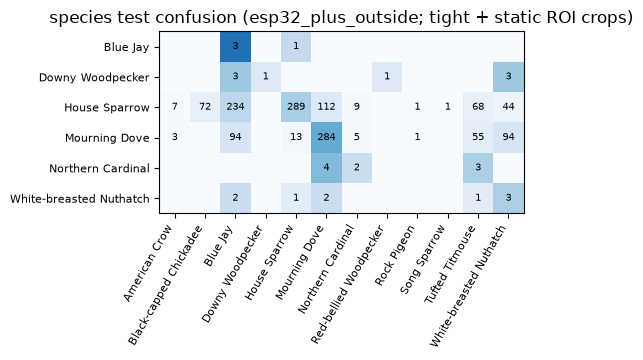

/home/joe/venvs/ESPclassifier/lib/python3.12/site-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)
Corrupt JPEG data: premature end of data segment


,model,input,n,top1
0,old species (Oct 9),tight test crops,789,0.010
1,old species (Oct 9),whole single-species test frames (as deployed),453,0.000
2,new species v4 (esp32_plus_outside),tight test crops,789,0.504
3,new species v4 (esp32_plus_outside),static-ROI test crops,627,0.276


In [14]:
def species_scores(path, table):
    ds = make_eval_ds([records[i]["jpeg"] for i in table["index"]],
                      table[["left", "top", "right", "bottom"]].to_numpy(np.int32), SPECIES_IMG)
    return tflite_run(path, ds)


def species_metrics(truth_names, probs, classes):
    idx = {c: k for k, c in enumerate(classes)}
    known = np.array([t in idx for t in truth_names])
    truth = np.array([idx.get(t, -1) for t in truth_names])
    top = np.argsort(-probs, axis=1)
    top1 = top[:, 0] == truth
    top3 = np.any(top[:, :3] == truth[:, None], axis=1)
    recalls = {classes[c]: float(np.mean(top1[truth == c])) for c in np.unique(truth[known])}
    return {"n": int(known.sum()), "top1": float(top1[known].mean()) if known.any() else float("nan"),
            "top3": float(top3[known].mean()) if known.any() else float("nan"),
            "macro_recall": float(np.mean(list(recalls.values()))) if recalls else float("nan"),
            "not_in_label_set": int((~known).sum())}, recalls


species_rows, per_class_rows = [], []
for arm, info in arm_results.items():
    for split, table in (("validation", species_val_all), ("test", species_test_all)):
        _, probs, sp_info = species_scores(info["uint8"], table)
        info[f"{split}_probs"], info["tensor_info"] = probs, sp_info
        for kind in ("all", "tight", "loose", "static_roi"):
            mask = np.ones(len(table), bool) if kind == "all" else table["kind"].eq(kind).to_numpy()
            if not mask.any():
                continue
            m, recalls = species_metrics(table["species"].to_numpy()[mask], probs[mask], info["classes"])
            species_rows.append({"arm": arm, "split": split, "crops": kind, **m})
            if split == "test" and kind == "all":
                per_class_rows += [{"arm": arm, "species": c, "test_recall": v,
                                    "test_crops": int((table["species"] == c).sum()),
                                    "camera_train_boxes": int((train_boxes["species"] == c).sum())} for c, v in recalls.items()]
species_results = pd.DataFrame(species_rows)
species_per_class = pd.DataFrame(per_class_rows)
species_results.to_csv(SP_DIR / "results.csv", index=False)
species_per_class.to_csv(SP_DIR / "per_class_test_recall.csv", index=False)
display(species_results.round(3)); display(species_per_class.round(3))

best = arm_results[best_arm]
classes = best["classes"]
val_probs = best["validation_probs"]
val_truth = species_val_all["species"].map({c: k for k, c in enumerate(classes)}).fillna(-1).to_numpy(int)
conf, pred = val_probs.max(axis=1), val_probs.argmax(axis=1)
suggested = 1.0
for t in np.unique(np.round(conf, 3)):
    keep = conf >= t
    if keep.sum() >= 20 and np.mean(pred[keep] == val_truth[keep]) >= 0.90:
        suggested = float(t); break
test_conf = best["test_probs"].max(axis=1)
print(f"suggested_min_confidence {suggested:.3f}: names {np.mean(test_conf >= suggested):.1%} of test crops")

# confusion matrix, test tight + static_roi crops, selected arm
present = sorted(set(species_test_all["species"]) & set(classes))
mask = (species_test_all["kind"].isin(["tight", "static_roi"]) & species_test_all["species"].isin(present)).to_numpy()
if present:
    idx = {c: k for k, c in enumerate(classes)}
    matrix = pd.crosstab(pd.Categorical(species_test_all["species"][mask], categories=present),
                         pd.Categorical([classes[k] for k in best["test_probs"][mask].argmax(axis=1)]),
                         rownames=["true"], colnames=["predicted"], dropna=False)
    matrix = matrix.loc[:, (matrix.sum(axis=0) > 0)]
    matrix.to_csv(SP_DIR / "test_confusion.csv")
    fig, ax = plt.subplots(figsize=(1 + 0.55 * matrix.shape[1], 1 + 0.45 * matrix.shape[0]))
    ax.imshow(matrix.to_numpy() / np.maximum(matrix.to_numpy().sum(axis=1, keepdims=True), 1), cmap="Blues", vmin=0, vmax=1)
    ax.set_xticks(range(matrix.shape[1]), matrix.columns, rotation=60, ha="right", fontsize=8)
    ax.set_yticks(range(matrix.shape[0]), matrix.index, fontsize=8)
    for (r, c), v in np.ndenumerate(matrix.to_numpy()):
        if v:
            ax.text(c, r, int(v), ha="center", va="center", fontsize=7)
    ax.set_title(f"species test confusion ({best_arm}; tight + static ROI crops)")
    plt.tight_layout(); plt.savefig(SP_DIR / "test_confusion.png", dpi=130); plt.show()

# ---- selected model files + contract at the species/ root ----
import shutil
for src, name in ((best["uint8"], "model_uint8.tflite"), (best["float"], "model_float32.tflite"),
                  (best["dir"] / "labels.txt", "labels.txt")):
    shutil.copyfile(src, SP_DIR / name)
species_contract = {
    "model_file": "model_uint8.tflite", "float_model_file": "model_float32.tflite", "labels_file": "labels.txt",
    "task": "species classification of one bird crop", "arm": best_arm, "classes": classes,
    "camera_trained_classes": sorted(train_boxes["species"].unique()),
    "outside_only_classes": sorted(set(classes) - set(train_boxes["species"])),
    "input_shape": best["tensor_info"]["input_shape"], "input_dtype": best["tensor_info"]["input_dtype"],
    "input_quantization": best["tensor_info"]["input_quantization"],
    "output_dtype": best["tensor_info"]["output_dtype"], "output_quantization": best["tensor_info"]["output_quantization"],
    "output": "softmax probabilities in labels.txt order",
    "geometry": "bird_crop_then_letterbox", "geometry_location": "outside the model",
    "crop": "the isBird selected crop (motion blob / static ROI), or a detector box expanded to give the bird 35-85% of the crop side",
    "trained_bird_fraction_of_crop_side": list(SPECIES_BIRD_FRACTION),
    "color_order": "RGB", "jpeg_decode_channels": 3, "resize_method": "TensorFlow bilinear", "resize_antialias": True,
    "letterbox_padding_value": 0, "numeric_scaling": "[0,255] to [-1,1] inside the model",
    "suggested_min_confidence": suggested,
    "not_for": "whole frames: the current server's species path letterboxes the whole frame; see DEPLOY.md",
}
write_json(SP_DIR / "species_contract.json", species_contract)

# ---- old species model (Oct 9, 179 classes, whole-frame letterbox) ----
old_species_rows = []
try:
    old_dir = portable_path(OLD_SPECIES_DIR)
    old_labels = [l.strip() for l in (old_dir / "labels.txt").read_text(encoding="utf-8").splitlines() if l.strip()]
    old_norm = [CUB_ALIASES.get(norm_name(l), norm_name(l)) for l in old_labels]
    old_path = old_dir / "model_float32.tflite"
    tight = species_test_all[species_test_all["kind"].eq("tight")].reset_index(drop=True)
    _, old_probs, _ = species_scores(old_path, tight)
    hits = [old_norm[k] == norm_name(t) for k, t in zip(old_probs.argmax(axis=1), tight["species"])]
    old_species_rows.append({"model": "old species (Oct 9)", "input": "tight test crops", "n": len(hits), "top1": float(np.mean(hits))})
    single = [i for i in by_split["test"] if records[i]["has_bird"] and len(set(records[i]["species"]) - {""}) == 1]
    whole_ds = make_eval_ds([records[i]["jpeg"] for i in single], [(0, 0, records[i]["width"], records[i]["height"]) for i in single], 224)
    _, old_whole, _ = tflite_run(old_path, whole_ds)
    hits = [old_norm[k] == norm_name(records[i]["species"][0]) for k, i in zip(old_whole.argmax(axis=1), single)]
    old_species_rows.append({"model": "old species (Oct 9)", "input": "whole single-species test frames (as deployed)",
                             "n": len(hits), "top1": float(np.mean(hits))})
except Exception as error:
    print("old species comparison skipped:", repr(error))
new_tight = species_results.query("arm == @best_arm and split == 'test' and crops == 'tight'")
new_roi = species_results.query("arm == @best_arm and split == 'test' and crops == 'static_roi'")
for label, part in (("tight test crops", new_tight), ("static-ROI test crops", new_roi)):
    if len(part):
        old_species_rows.append({"model": f"new species v4 ({best_arm})", "input": label, "n": int(part["n"].iloc[0]), "top1": float(part["top1"].iloc[0])})
species_comparison = pd.DataFrame(old_species_rows)
species_comparison.to_csv(SP_DIR / "old_vs_new.csv", index=False)
display(species_comparison.round(3))


## 13. Run summary and deployment notes


In [15]:
def headline(table, **query):
    part = table
    for k, v in query.items():
        part = part[part[k].eq(v)]
    return part.iloc[0].to_dict() if len(part) else {}


summary = {
    "run": RUN_NAME, "created_utc": created_utc.isoformat(), "quick_run": QUICK_RUN,
    "data": {"images": len(records), "inventory_sha256": sha256_file(portable_path(INVENTORY_CSV)),
             "annotations_sha256": sha256_file(portable_path(ANNOTATIONS_CSV)),
             "split_images": frames["split"].value_counts().to_dict(),
             "validation_scenes": sorted(scenes.index[scenes["split"].eq("validation")]),
             "test_scenes": sorted(scenes.index[scenes["split"].eq("test")]),
             "outside": outside_report},
    "isbird": {"minutes": isbird_minutes, "uint8_output_threshold": RAW_T, "probability_threshold": PROB_T,
               "test_all": headline(isbird_results, split="test", slice="all"),
               "test_static_roi": headline(isbird_results, split="test", slice="kind=static_roi"),
               "files": [str(ISB_DIR / n) for n in ("model_uint8.tflite", "inference_contract.json", "threshold.json")]},
    "species": {"selected_arm": best_arm,
                "arms": {a: {"classes": len(i["classes"]), "best_val_macro_recall": i["best_val_macro_recall"], "minutes": i["minutes"]}
                         for a, i in arm_results.items()},
                "test_selected_all": headline(species_results, arm=best_arm, split="test", crops="all"),
                "suggested_min_confidence": suggested},
    "config": {k: v for k, v in globals().items() if k.isupper() and isinstance(v, (int, float, str, bool, list, tuple, dict))},
}
write_json(RUN_DIR / "run_summary.json", summary)

deploy = f"""# Deploying {RUN_NAME}

## isBird (drop-in)
Copy these three files from `isbird/` into one folder on the Pi:
`model_uint8.tflite`, `inference_contract.json`, `threshold.json`.
Start the hub with `--is-bird-model <folder>/model_uint8.tflite`. The server validates the contract at
startup (geometry `selected_crop_then_letterbox`, black letterbox, uint8 rule `raw >= {RAW_T}`).
This replaces the bounding-box detector as the gate. Leave `--collection-mode` off; that mode is detector-only.

## Species (needs a server change first)
`species/model_uint8.tflite` + `species/labels.txt` were trained on bird crops. `bird_inference.py`
currently letterboxes the whole frame for species, which this model was not trained for.
The change: in `BirdInferenceEngine.infer`, build `species_pixels` from the same selected crop the
is-bird model scores (`rgb[top:bottom, left:right]`), or from the top detector box expanded so the bird
fills about half of the crop side. Show the top label only when its probability is at least
{suggested:.2f} (`suggested_min_confidence`); below that, record "unidentified bird".
"""
(RUN_DIR / "DEPLOY.md").write_text(deploy, encoding="utf-8")
print(deploy)
print(json.dumps(json_safe({k: summary[k] for k in ("isbird", "species")}), indent=2)[:4000])


# Deploying esp32_classifiers_v4_20261119T064312Z

## isBird (drop-in)
Copy these three files from `isbird/` into one folder on the Pi:
`model_uint8.tflite`, `inference_contract.json`, `threshold.json`.
Start the hub with `--is-bird-model <folder>/model_uint8.tflite`. The server validates the contract at
startup (geometry `selected_crop_then_letterbox`, black letterbox, uint8 rule `raw >= 231`).
This replaces the bounding-box detector as the gate. Leave `--collection-mode` off; that mode is detector-only.

## Species (needs a server change first)
`species/model_uint8.tflite` + `species/labels.txt` were trained on bird crops. `bird_inference.py`
currently letterboxes the whole frame for species, which this model was not trained for.
The change: in `BirdInferenceEngine.infer`, build `species_pixels` from the same selected crop the
is-bird model scores (`rgb[top:bottom, left:right]`), or from the top detector box expanded so the bird
fills about half of the crop side. Show the top label o